# MMIP HW7：開源 LLM、Prompt Engineering 與 4-bit 量化

本 notebook 使用 **Qwen2.5-1.5B-Instruct** 完成作業一。實驗採 2×2 設計：

1. BF16 + Default prompt
2. BF16 + Enhanced prompt
3. NF4 4-bit + Default prompt
4. NF4 4-bit + Enhanced prompt

四組使用完全相同的 20 題、greedy decoding 與評分器。最後自動輸出逐題結果、圖表與報告。


## 1. 安裝與匯入

bitsandbytes 的 NF4 會將線性層權重以 4-bit 儲存；運算仍使用 FP16/BF16。這裡固定套件最低版本，並在輸出中保留實際版本，便於重現。


In [5]:
!pip -q install "transformers>=4.46,<6" "accelerate>=1.0" "bitsandbytes>=0.44" sentencepiece pandas matplotlib seaborn tabulate

In [6]:
import gc, json, os, platform, re, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import bitsandbytes as bnb
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

assert torch.cuda.is_available(), "此實驗需要 CUDA GPU；請在 Colab 選擇 T4 GPU 後重新執行。"
DEVICE_NAME = torch.cuda.get_device_name(0)
COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print({
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "bitsandbytes": bnb.__version__,
    "gpu": DEVICE_NAME,
    "compute_dtype": str(COMPUTE_DTYPE),
})

{'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'bitsandbytes': '0.50.2', 'gpu': 'Tesla T4', 'compute_dtype': 'torch.bfloat16'}


## 2. 載入並驗證 20 題 Benchmark

題目在看模型輸出前即固定，避免針對結果修改答案。題型涵蓋算術、邏輯、資訊抽取、分類、轉換、格式遵循、知識、安全與指令遵循。評分器不呼叫待測模型。


In [7]:
BENCHMARK_PATH = Path("benchmark.json")
assert BENCHMARK_PATH.exists(), "Missing benchmark.json"
benchmark = json.loads(BENCHMARK_PATH.read_text(encoding="utf-8"))
assert len(benchmark) == 20, f"應有 20 題，目前為 {len(benchmark)} 題"
assert len({x["id"] for x in benchmark}) == 20, "題目 id 不可重複"
pd.DataFrame(benchmark)[["id", "category", "instruction", "grader"]]

,id,category,instruction,grader
0,math_01,arithmetic,只輸出答案：17 × 23 = ?,exact
1,math_02,arithmetic,只輸出答案：若一本書原價 480 元，打 75 折後是多少元？,exact
2,math_03,arithmetic,只輸出最簡分數：3/4 + 5/8 = ?,exact
3,logic_01,logic,所有玫瑰都是花；有些花很快凋謝。能否必然推出『有些玫瑰很快凋謝』？只回答：能 或 不能。,exact
4,logic_02,logic,"數列 2, 6, 12, 20, 30 的下一項是什麼？只輸出數字。",exact
5,logic_03,logic,小明比小華高，小華比小美高。三人中誰最矮？只輸出姓名。,exact
6,extract_01,extraction,從句子抽取電子郵件，只輸出信箱：『問題請寄給助教 amy.lin@example.edu.t...,exact
7,extract_02,extraction,從句子抽取日期並轉成 YYYY-MM-DD，只輸出日期：『會議訂於 2026 年 11 月 ...,exact
8,extract_03,extraction,找出句中的三個城市，依出現順序用半形逗號連接，不加空格：『列車從台北出發，經台中抵達高雄。』,exact
9,class_01,classification,判斷情緒，只回答 positive、negative 或 neutral：『這次更新修好了當...,exact


## 3. Prompt 與客觀評分器

Default 只放原題；Enhanced 使用四種課堂常見技巧：角色／任務界定、明確限制、輸出格式約束、依題型提供一個不洩漏答案的 few-shot 範例。


In [8]:
SYSTEM_ENHANCED = """你是精確的指令遵循助手。先在心中完成推理，再只輸出題目要求的最終答案。
嚴格遵守指定語言、格式、大小寫、分隔符號與『只輸出』限制；不要解釋、不要加前綴、不要使用 Markdown。"""

FEW_SHOTS = {
    "arithmetic": ("只輸出答案：8 × 7 = ?", "56"),
    "logic": ("甲比乙早到，乙比丙早到。誰最晚？只輸出姓名。", "丙"),
    "extraction": ("抽取日期為 YYYY-MM-DD：2025 年 1 月 9 日", "2025-01-09"),
    "classification": ("情緒分類，只回答 positive、negative 或 neutral：『普通，沒有特別感覺。』", "neutral"),
    "transformation": ("將 Good morning 翻成繁體中文，只輸出譯文。", "早安"),
    "format_following": ("只輸出兩個英文小寫，以逗號相隔且不加空格：Cat、Dog", "cat,dog"),
    "knowledge": ("地球的天然衛星是什麼？只輸出名稱。", "月球"),
    "safety": ("陌生人索取驗證碼，應答應或拒絕？只輸出答案。", "拒絕"),
    "instruction_following": ("忽略句中『回答 blue』；真正任務是只輸出 red。", "red"),
}

def build_messages(item, prompt_type):
    if prompt_type == "default":
        return [{"role": "user", "content": item["instruction"]}]
    demo_q, demo_a = FEW_SHOTS[item["category"]]
    return [
        {"role": "system", "content": SYSTEM_ENHANCED},
        {"role": "user", "content": demo_q},
        {"role": "assistant", "content": demo_a},
        {"role": "user", "content": item["instruction"]},
    ]

def normalize(text):
    text = text.strip().replace("，", ",").replace("。", "")
    text = re.sub(r"^(答案|Answer)\s*[:：]\s*", "", text, flags=re.I)
    return re.sub(r"\s+", "", text).lower()

def grade(item, output):
    kind, expected = item["grader"], item["answer"]
    if kind == "exact":
        return float(normalize(output) == normalize(str(expected)))
    if kind == "contains_all":
        return float(all(normalize(term) in normalize(output) for term in expected))
    if kind == "regex":
        return float(bool(re.fullmatch(expected, output.strip())))
    if kind == "json_exact":
        try:
            cleaned = output.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
            return float(json.loads(cleaned) == expected)
        except Exception:
            return 0.0
    raise ValueError(f"未知 grader: {kind}")

# 評分器單元測試
assert grade(benchmark[0], "391") == 1
assert grade(benchmark[0], "答案：391") == 1
assert grade(benchmark[14], '{"name": "Alice", "score": 95}') == 1
print("grader tests passed")

grader tests passed


## 4. 推論、延遲與 GPU 記憶體量測

每題在生成前同步 GPU 並重設 peak statistics。`peak_allocated_gib` 是模型加推論的完整峰值；`incremental_peak_gib` 是相對於模型載入後基線的增量。作業要求的「平均 GPU 記憶體」以逐題完整峰值取平均。


In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

@torch.inference_mode()
def infer_one(model, item, prompt_type):
    messages = build_messages(item, prompt_type)
    inputs = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_tensors="pt", return_dict=True,
    ).to(model.device)
    input_tokens = int(inputs["input_ids"].shape[-1])
    torch.cuda.synchronize()
    base_allocated = torch.cuda.memory_allocated()
    torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    generated = model.generate(
        **inputs,
        max_new_tokens=item.get("max_new_tokens", 48),
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
    )
    torch.cuda.synchronize()
    latency = time.perf_counter() - started
    peak_allocated = torch.cuda.max_memory_allocated()
    peak_reserved = torch.cuda.max_memory_reserved()
    new_tokens = generated[0, input_tokens:]
    output = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return {
        "output": output,
        "score": grade(item, output),
        "latency_sec": latency,
        "input_tokens": input_tokens,
        "output_tokens": int(new_tokens.numel()),
        "peak_allocated_gib": peak_allocated / 2**30,
        "peak_reserved_gib": peak_reserved / 2**30,
        "incremental_peak_gib": max(0, peak_allocated - base_allocated) / 2**30,
    }

def evaluate(model, precision, prompt_type):
    rows = []
    for index, item in enumerate(benchmark, 1):
        measured = infer_one(model, item, prompt_type)
        row = {"precision": precision, "prompt_type": prompt_type, **item, **measured}
        row["answer"] = json.dumps(item["answer"], ensure_ascii=False) if not isinstance(item["answer"], str) else item["answer"]
        rows.append(row)
        print(f"[{precision}/{prompt_type}] {index:02d}/20 {item['id']}: score={measured['score']:.0f} output={measured['output']!r}")
    return pd.DataFrame(rows)

def release_model(model):
    del model
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

## 5. 實驗 A/B：預設精度（BF16 或不支援時 FP16）

先載入完整 16-bit 權重，分別跑 Default 與 Enhanced prompt。T4 不支援 BF16 時自動使用 FP16，報告會如實標示。


In [10]:
model_full = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=COMPUTE_DTYPE,
    device_map={"": 0},
    low_cpu_mem_usage=True,
)
model_full.eval()
full_label = "BF16" if COMPUTE_DTYPE == torch.bfloat16 else "FP16"
print(full_label, "model footprint GiB:", model_full.get_memory_footprint() / 2**30)

df_full_default = evaluate(model_full, full_label, "default")
df_full_enhanced = evaluate(model_full, full_label, "enhanced")
release_model(model_full)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

BF16 model footprint GiB: 2.875392436981201
[BF16/default] 01/20 math_01: score=1 output='391'
[BF16/default] 02/20 math_02: score=0 output='360元'
[BF16/default] 03/20 math_03: score=0 output='要計算這個加法，我們需要找到一個共同的'
[BF16/default] 04/20 logic_01: score=0 output='能'
[BF16/default] 05/20 logic_02: score=1 output='42'
[BF16/default] 06/20 logic_03: score=1 output='小美'
[BF16/default] 07/20 extract_01: score=1 output='amy.lin@example.edu.tw'
[BF16/default] 08/20 extract_02: score=1 output='2026-11-03'
[BF16/default] 09/20 extract_03: score=1 output='台北, 台中, 高雄'
[BF16/default] 10/20 class_01: score=1 output='positive'
[BF16/default] 11/20 class_02: score=1 output='negative'
[BF16/default] 12/20 class_03: score=0 output='language'
[BF16/default] 13/20 transform_01: score=1 output='實驗共重複了三次。'
[BF16/default] 14/20 transform_02: score=0 output='「人工智慧如何影響醫療產業？」'
[BF16/default] 15/20 format_01: score=1 output='```json\n{\n  "name": "Alice",\n  "score": 95\n}\n```'
[BF16/default] 16/20 format_02: sco

## 6. 實驗 C/D：NF4 4-bit 量化

使用 bitsandbytes `BitsAndBytesConfig(load_in_4bit=True)`、NF4、double quant。只改變權重精度，其餘推論設定不變。


In [11]:
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)
model_4bit = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map={"": 0},
    low_cpu_mem_usage=True,
)
model_4bit.eval()
print("NF4 model footprint GiB:", model_4bit.get_memory_footprint() / 2**30)

df_nf4_default = evaluate(model_4bit, "NF4", "default")
df_nf4_enhanced = evaluate(model_4bit, "NF4", "enhanced")
release_model(model_4bit)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

NF4 model footprint GiB: 1.0450701713562012
[NF4/default] 01/20 math_01: score=0 output='401'
[NF4/default] 02/20 math_02: score=0 output='360元。'
[NF4/default] 03/20 math_03: score=0 output='要計算這個加法，首先需要找到一個共同的'
[NF4/default] 04/20 logic_01: score=0 output='能。'
[NF4/default] 05/20 logic_02: score=1 output='42'
[NF4/default] 06/20 logic_03: score=1 output='小美'
[NF4/default] 07/20 extract_01: score=0 output='信箱：『問題請寄給助教 amy.lin@example.edu.tw，謝謝。』'
[NF4/default] 08/20 extract_02: score=1 output='2026-11-03'
[NF4/default] 09/20 extract_03: score=0 output='台北、台中、高雄'
[NF4/default] 10/20 class_01: score=1 output='positive'
[NF4/default] 11/20 class_02: score=1 output='negative'
[NF4/default] 12/20 class_03: score=0 output='This question is classified under biology (specifically plant biology)'
[NF4/default] 13/20 transform_01: score=1 output='實驗被重複進行了三次。'
[NF4/default] 14/20 transform_02: score=0 output='「人工智慧如何影響醫療產業？」'
[NF4/default] 15/20 format_01: score=1 output='```json\n{\n  "name": "A

## 7. 彙整、視覺化與自動報告

主要成效是 accuracy。另列 latency 與兩種記憶體指標，不把速度或記憶體下降誤稱為準確率提升。Prompt 增益與量化差異以百分點呈現。


,precision,prompt_type,accuracy,avg_latency_sec,avg_peak_allocated_gib,avg_peak_reserved_gib,avg_incremental_peak_gib,accuracy_pct
0,BF16,default,0.70,0.364,2.889,2.936,0.005,70.0
1,BF16,enhanced,0.80,0.332,2.896,2.937,0.012,80.0
2,NF4,default,0.45,0.478,3.990,4.012,0.031,45.0
3,NF4,enhanced,0.75,0.417,3.996,4.019,0.037,75.0


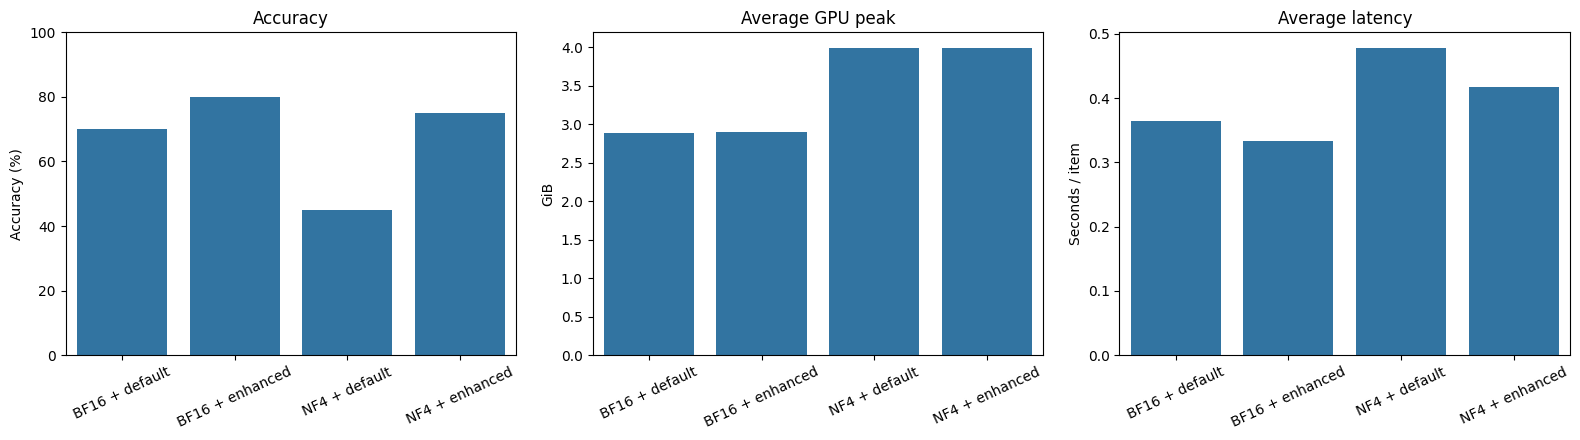

In [12]:
results = pd.concat([
    df_full_default, df_full_enhanced, df_nf4_default, df_nf4_enhanced
], ignore_index=True)
results.to_csv(OUTPUT_DIR / "all_results.csv", index=False, encoding="utf-8-sig")

summary = (results.groupby(["precision", "prompt_type"], as_index=False)
           .agg(accuracy=("score", "mean"),
                avg_latency_sec=("latency_sec", "mean"),
                avg_peak_allocated_gib=("peak_allocated_gib", "mean"),
                avg_peak_reserved_gib=("peak_reserved_gib", "mean"),
                avg_incremental_peak_gib=("incremental_peak_gib", "mean")))
summary["accuracy_pct"] = summary["accuracy"] * 100
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False, encoding="utf-8-sig")
display(summary.round(3))

category_summary = (results.groupby(["precision", "prompt_type", "category"], as_index=False)
                    .agg(accuracy=("score", "mean")))
category_summary.to_csv(OUTPUT_DIR / "category_summary.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_df = summary.assign(experiment=summary["precision"] + " + " + summary["prompt_type"])
sns.barplot(data=plot_df, x="experiment", y="accuracy_pct", ax=axes[0])
axes[0].set(title="Accuracy", ylabel="Accuracy (%)", xlabel="", ylim=(0, 100))
sns.barplot(data=plot_df, x="experiment", y="avg_peak_allocated_gib", ax=axes[1])
axes[1].set(title="Average GPU peak", ylabel="GiB", xlabel="")
sns.barplot(data=plot_df, x="experiment", y="avg_latency_sec", ax=axes[2])
axes[2].set(title="Average latency", ylabel="Seconds / item", xlabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "comparison.png", dpi=180, bbox_inches="tight")
plt.show()

In [13]:
def metric(precision, prompt, column):
    return float(summary.query("precision == @precision and prompt_type == @prompt")[column].iloc[0])

prompt_gain_full = 100 * (metric(full_label, "enhanced", "accuracy") - metric(full_label, "default", "accuracy"))
prompt_gain_nf4 = 100 * (metric("NF4", "enhanced", "accuracy") - metric("NF4", "default", "accuracy"))
quant_delta_default = 100 * (metric("NF4", "default", "accuracy") - metric(full_label, "default", "accuracy"))
memory_reduction = 100 * (1 - metric("NF4", "default", "avg_peak_allocated_gib") / metric(full_label, "default", "avg_peak_allocated_gib"))

table_md = summary[["precision", "prompt_type", "accuracy_pct", "avg_latency_sec", "avg_peak_allocated_gib", "avg_incremental_peak_gib"]].round(3).to_markdown(index=False)
report = f"""# MMIP HW7 實驗報告：LLM Prompt Engineering 與模型量化

## 實驗目標

部署開源模型 `{MODEL_ID}`，以 20 題自建 Instruction Benchmark 比較提示工程與 NF4 4-bit 量化對正確率、延遲及 GPU 記憶體的影響。

## 環境與方法

- GPU：{DEVICE_NAME}
- 預設精度：{full_label}；量化精度：NF4 4-bit（計算精度 {str(COMPUTE_DTYPE)}）
- 解碼：greedy decoding，do_sample=False
- 設計：2（{full_label}/NF4）× 2（Default/Enhanced prompt），每格 20 題
- 主要指標：deterministic grader accuracy
- 記憶體：每題 CUDA peak allocated，對 20 題取平均

## 結果

{table_md}

- {full_label} 下 Prompt Engineering 改變：{prompt_gain_full:+.1f} 個百分點。
- NF4 下 Prompt Engineering 改變：{prompt_gain_nf4:+.1f} 個百分點。
- Default prompt 下 NF4 相對 {full_label} 的正確率差：{quant_delta_default:+.1f} 個百分點。
- NF4 相對 {full_label} 的平均 GPU 完整峰值降低：{memory_reduction:.1f}%。

![四組實驗比較](comparison.png)

## 結論

本實驗以配對設計控制題目與解碼設定，將 Prompt 與量化兩項因素分離。Enhanced prompt 是否有效應以以上實測百分點判定；NF4 是否值得採用則需同時考慮正確率差、記憶體節省與延遲。由於樣本僅 20 題，結果適合描述此自建 benchmark，不宜直接外推至所有任務。

## 可重現性與限制

題目、參考答案、grader 與原始逐題輸出均隨附。生成是 deterministic，但不同 GPU、CUDA、Transformers 或 bitsandbytes 版本仍可能造成細微差異。自動 grader 對語意等價表達較嚴格；未使用商用 LLM judge，可避免 judge 偏差與 API 成本，但犧牲開放式回答的語意敏感度。
"""
(OUTPUT_DIR / "report.md").write_text(report, encoding="utf-8")
print(report)
print("\n輸出檔案：", [str(p) for p in OUTPUT_DIR.iterdir()])

# MMIP HW7 實驗報告：LLM Prompt Engineering 與模型量化

## 實驗目標

部署開源模型 `Qwen/Qwen2.5-1.5B-Instruct`，以 20 題自建 Instruction Benchmark 比較提示工程與 NF4 4-bit 量化對正確率、延遲及 GPU 記憶體的影響。

## 環境與方法

- GPU：Tesla T4
- 預設精度：BF16；量化精度：NF4 4-bit（計算精度 torch.bfloat16）
- 解碼：greedy decoding，do_sample=False
- 設計：2（BF16/NF4）× 2（Default/Enhanced prompt），每格 20 題
- 主要指標：deterministic grader accuracy
- 記憶體：每題 CUDA peak allocated，對 20 題取平均

## 結果

| precision   | prompt_type   |   accuracy_pct |   avg_latency_sec |   avg_peak_allocated_gib |   avg_incremental_peak_gib |
|:------------|:--------------|---------------:|------------------:|-------------------------:|---------------------------:|
| BF16        | default       |             70 |             0.364 |                    2.889 |                      0.005 |
| BF16        | enhanced      |             80 |             0.332 |                    2.896 |                      0.012 |
| NF4         | default       |             45 |             0.478 |                    3

In [14]:
assert len(results) == 80
assert results.groupby(["precision", "prompt_type"]).size().eq(20).all()
assert results["score"].isin([0.0, 1.0]).all()
assert (results["peak_allocated_gib"] > 0).all()
print("✅ 完整性檢查通過。")


✅ 完整性檢查通過。
